In [1]:
import pandas as pd

Load the E-Commerce Dataset

Task 1: E-Commerce Dataset Cleaning

In [2]:
df=pd.read_csv("ecommerce sales dataset.csv")

In [3]:
df.head()

,Order ID,Customer ID,Product Name,Category,Quantity,Unit Price,Total Amount,Order Date,Payment Mode,Delivery Status,City
0,ORD0001,CUST1189,T-Shirt,Clothing,3,699,2097,2025-03-13,Net Banking,Delivered,Nashik
1,ORD0002,CUST1152,Headphones,Electronics,5,2499,12495,2025-04-10,Debit Card,Delivered,NaN
2,ORD0003,CUST1277,Python Book,Books,2,799,1598,2025-07-11,UPI,Delivered,Aurangabad
3,ORD0004,CUST1170,Smartphone,Electronics,1,18999,18999,2025-02-28,Cash on Delivery,Returned,Nashik
4,ORD0005,NaN,Shoes,Clothing,1,1999,1999,2025-05-11,Net Banking,Delivered,Mumbai


Check dataset size

In [4]:
df.shape

(1010, 11)

Check data types

In [5]:
df.dtypes

Order ID           object
Customer ID        object
Product Name       object
Category           object
Quantity            int64
Unit Price          int64
Total Amount        int64
Order Date         object
Payment Mode       object
Delivery Status    object
City               object
dtype: object

step 3:Check missing values

In [6]:
df.isnull().sum()

Order ID            0
Customer ID        15
Product Name        0
Category            0
Quantity            0
Unit Price          0
Total Amount        0
Order Date          0
Payment Mode       10
Delivery Status     0
City                8
dtype: int64

Calculate missing percentage

In [7]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_percentage

Order ID           0.000000
Customer ID        1.485149
Product Name       0.000000
Category           0.000000
Quantity           0.000000
Unit Price         0.000000
Total Amount       0.000000
Order Date         0.000000
Payment Mode       0.990099
Delivery Status    0.000000
City               0.792079
dtype: float64

Create a proper missing-value report

In [8]:
missing_report = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().sum() / len(df) * 100).round(2)
})

missing_report

,Missing Count,Missing Percentage
Order ID,0,0.00
Customer ID,15,1.49
Product Name,0,0.00
Category,0,0.00
Quantity,0,0.00
Unit Price,0,0.00
Total Amount,0,0.00
Order Date,0,0.00
Payment Mode,10,0.99
Delivery Status,0,0.00


Show only columns that contain missing values

In [9]:
missing_report[missing_report["Missing Count"] > 0]

,Missing Count,Missing Percentage
Customer ID,15,1.49
Payment Mode,10,0.99
City,8,0.79


Save the report

In [10]:
missing_report.to_csv(
    "missing_values_report.csv",
    index=True
)

Missing Value Analysis:
Missing values were checked column by column. The missing-value count and percentage were calculated to understand the extent of incomplete data. Categorical missing values will be handled using an appropriate placeholder such as Unknown, while invalid or non-critical records will be handled based on their impact on analysis.

Step 4 — Find and Analyze Duplicate Records

In [11]:
df.duplicated().sum()

7

Display the duplicate rows

In [12]:
df[df.duplicated()]

,Order ID,Customer ID,Product Name,Category,Quantity,Unit Price,Total Amount,Order Date,Payment Mode,Delivery Status,City
1000,ORD0001,CUST1189,T-Shirt,Clothing,3,699,2097,2025-03-13,Net Banking,Delivered,Nashik
1002,ORD0003,CUST1277,Python Book,Books,2,799,1598,2025-07-11,UPI,Delivered,Aurangabad
1003,ORD0004,CUST1170,Smartphone,Electronics,1,18999,18999,2025-02-28,Cash on Delivery,Returned,Nashik
1005,ORD0006,CUST1053,Perfume,Beauty,2,1299,2598,2025-09-22,Credit Card,Shipped,Navi Mumbai
1007,ORD0008,CUST1191,Jeans,Clothing,2,1499,2998,2025-09-17,Credit Card,Processing,Mumbai
1008,ORD0009,CUST1296,Shoes,Clothing,4,1999,7996,2025-07-09,Net Banking,Delivered,Mumbai
1009,ORD0010,CUST1252,Dinner Set,Home & Kitchen,2,1299,2598,2025-08-05,Cash on Delivery,Delivered,Kolhapur


Show all copies of duplicate records

In [13]:
duplicates = df[df.duplicated(keep=False)]

duplicates

,Order ID,Customer ID,Product Name,Category,Quantity,Unit Price,Total Amount,Order Date,Payment Mode,Delivery Status,City
0,ORD0001,CUST1189,T-Shirt,Clothing,3,699,2097,2025-03-13,Net Banking,Delivered,Nashik
2,ORD0003,CUST1277,Python Book,Books,2,799,1598,2025-07-11,UPI,Delivered,Aurangabad
3,ORD0004,CUST1170,Smartphone,Electronics,1,18999,18999,2025-02-28,Cash on Delivery,Returned,Nashik
5,ORD0006,CUST1053,Perfume,Beauty,2,1299,2598,2025-09-22,Credit Card,Shipped,Navi Mumbai
7,ORD0008,CUST1191,Jeans,Clothing,2,1499,2998,2025-09-17,Credit Card,Processing,Mumbai
8,ORD0009,CUST1296,Shoes,Clothing,4,1999,7996,2025-07-09,Net Banking,Delivered,Mumbai
9,ORD0010,CUST1252,Dinner Set,Home & Kitchen,2,1299,2598,2025-08-05,Cash on Delivery,Delivered,Kolhapur
1000,ORD0001,CUST1189,T-Shirt,Clothing,3,699,2097,2025-03-13,Net Banking,Delivered,Nashik
1002,ORD0003,CUST1277,Python Book,Books,2,799,1598,2025-07-11,UPI,Delivered,Aurangabad
1003,ORD0004,CUST1170,Smartphone,Electronics,1,18999,18999,2025-02-28,Cash on Delivery,Returned,Nashik


Sort duplicate records by Order ID

In [14]:
duplicates.sort_values("Order ID")

,Order ID,Customer ID,Product Name,Category,Quantity,Unit Price,Total Amount,Order Date,Payment Mode,Delivery Status,City
0,ORD0001,CUST1189,T-Shirt,Clothing,3,699,2097,2025-03-13,Net Banking,Delivered,Nashik
1000,ORD0001,CUST1189,T-Shirt,Clothing,3,699,2097,2025-03-13,Net Banking,Delivered,Nashik
2,ORD0003,CUST1277,Python Book,Books,2,799,1598,2025-07-11,UPI,Delivered,Aurangabad
1002,ORD0003,CUST1277,Python Book,Books,2,799,1598,2025-07-11,UPI,Delivered,Aurangabad
3,ORD0004,CUST1170,Smartphone,Electronics,1,18999,18999,2025-02-28,Cash on Delivery,Returned,Nashik
1003,ORD0004,CUST1170,Smartphone,Electronics,1,18999,18999,2025-02-28,Cash on Delivery,Returned,Nashik
5,ORD0006,CUST1053,Perfume,Beauty,2,1299,2598,2025-09-22,Credit Card,Shipped,Navi Mumbai
1005,ORD0006,CUST1053,Perfume,Beauty,2,1299,2598,2025-09-22,Credit Card,Shipped,Navi Mumbai
7,ORD0008,CUST1191,Jeans,Clothing,2,1499,2998,2025-09-17,Credit Card,Processing,Mumbai
1007,ORD0008,CUST1191,Jeans,Clothing,2,1499,2998,2025-09-17,Credit Card,Processing,Mumbai


Check for repeated Order IDs

In [15]:
df["Order ID"].duplicated().sum()

10

In [16]:
duplicate_order_ids = df[
    df["Order ID"].duplicated(keep=False)
]

duplicate_order_ids.sort_values("Order ID")

,Order ID,Customer ID,Product Name,Category,Quantity,Unit Price,Total Amount,Order Date,Payment Mode,Delivery Status,City
0,ORD0001,CUST1189,T-Shirt,Clothing,3,699,2097,2025-03-13,Net Banking,Delivered,Nashik
1000,ORD0001,CUST1189,T-Shirt,Clothing,3,699,2097,2025-03-13,Net Banking,Delivered,Nashik
1,ORD0002,CUST1152,Headphones,Electronics,5,2499,12495,2025-04-10,Debit Card,Delivered,NaN
1001,ORD0002,CUST1152,Headphones,Electronics,5,2499,12495,2025-04-10,NaN,Delivered,Mumbai
2,ORD0003,CUST1277,Python Book,Books,2,799,1598,2025-07-11,UPI,Delivered,Aurangabad
1002,ORD0003,CUST1277,Python Book,Books,2,799,1598,2025-07-11,UPI,Delivered,Aurangabad
3,ORD0004,CUST1170,Smartphone,Electronics,1,18999,18999,2025-02-28,Cash on Delivery,Returned,Nashik
1003,ORD0004,CUST1170,Smartphone,Electronics,1,18999,18999,2025-02-28,Cash on Delivery,Returned,Nashik
4,ORD0005,NaN,Shoes,Clothing,1,1999,1999,2025-05-11,Net Banking,Delivered,Mumbai
1004,ORD0005,CUST1135,Shoes,Clothing,1,1999,1999,2025-05-11,Net Banking,Delivered,Mumbai


Check how many times each Order ID appears

In [17]:
order_id_counts = df["Order ID"].value_counts()

order_id_counts[order_id_counts > 1]

Order ID
ORD0001    2
ORD0007    2
ORD0010    2
ORD0009    2
ORD0008    2
ORD0002    2
ORD0006    2
ORD0004    2
ORD0003    2
ORD0005    2
Name: count, dtype: int64

Create a duplicate analysis report

In [18]:
duplicate_report = pd.DataFrame({
    "Total Rows": [len(df)],
    "Duplicate Rows": [df.duplicated().sum()],
    "Duplicate Order IDs": [
        df["Order ID"].duplicated().sum()
    ]
})

duplicate_report

,Total Rows,Duplicate Rows,Duplicate Order IDs
0,1010,7,10


In [19]:
duplicate_report.to_csv(
    "duplicate_analysis_report.csv",
    index=False
)

Duplicate Analysis:
Duplicate records were identified using the complete row values. Repeated Order IDs were also checked separately. Duplicate records were reviewed before removal to distinguish accidental copies from potentially valid repeated transactions.

Data Validation

Check negative or zero Quantity

In [20]:
invalid_quantity = df[df["Quantity"] <= 0]

invalid_quantity

,Order ID,Customer ID,Product Name,Category,Quantity,Unit Price,Total Amount,Order Date,Payment Mode,Delivery Status,City
196,ORD0197,CUST1179,Face Wash,Beauty,-1,399,-399,2025-08-02,UPI,Delivered,Kolhapur
480,ORD0481,CUST1025,Laptop,Electronics,-1,55000,-55000,2025-04-08,Net Banking,Delivered,Pune
528,ORD0529,CUST1264,Shampoo,Beauty,-1,599,-599,2025-09-15,Debit Card,Processing,Aurangabad
639,ORD0640,CUST1018,T-Shirt,Clothing,-1,699,-699,2025-05-28,Debit Card,Delivered,Ahilyanagar
827,ORD0828,CUST1246,Shoes,Clothing,-1,1999,-1999,2025-01-17,Debit Card,Delivered,Navi Mumbai


In [21]:
len(invalid_quantity)

5

Check zero or negative Unit Price

In [22]:
invalid_price = df[df["Unit Price"] <= 0]

invalid_price

,Order ID,Customer ID,Product Name,Category,Quantity,Unit Price,Total Amount,Order Date,Payment Mode,Delivery Status,City
208,ORD0209,CUST1152,Dinner Set,Home & Kitchen,4,0,0,2025-01-20,Credit Card,Cancelled,Kolhapur
268,ORD0269,CUST1124,Smartwatch,Electronics,4,0,0,2025-08-09,Credit Card,Delivered,Nagpur
818,ORD0819,CUST1069,Data Science Book,Books,1,0,0,2025-05-25,Credit Card,Delivered,Nagpur
826,ORD0827,CUST1276,Skin Cream,Beauty,2,0,0,2025-02-11,UPI,Delivered,Mumbai


In [23]:
len(invalid_price)

4

Check invalid Total Amount

In [24]:
df["Expected Total"] = df["Quantity"] * df["Unit Price"]

In [25]:
df["Amount Difference"] = (
    df["Total Amount"] - df["Expected Total"]
)

df[df["Amount Difference"] != 0]

,Order ID,Customer ID,Product Name,Category,Quantity,Unit Price,Total Amount,Order Date,Payment Mode,Delivery Status,City,Expected Total,Amount Difference


Check invalid dates

In [26]:
df["Order Date"] = pd.to_datetime(
    df["Order Date"],
    errors="coerce"
)

In [27]:
invalid_dates = df[df["Order Date"].isna()]

invalid_dates

,Order ID,Customer ID,Product Name,Category,Quantity,Unit Price,Total Amount,Order Date,Payment Mode,Delivery Status,City,Expected Total,Amount Difference
58,ORD0059,CUST1090,Laptop,Electronics,3,55000,165000,NaT,Net Banking,Cancelled,Satara,165000,0
482,ORD0483,CUST1262,Python Book,Books,2,799,1598,NaT,UPI,Delivered,Aurangabad,1598,0


In [28]:
len(invalid_dates)

2

Check inconsistent categories

In [29]:
df["Category"].value_counts(dropna=False)

Category
Electronics       297
Clothing          231
Home & Kitchen    192
Beauty            150
Books             120
electronics         7
 Electronics        7
CLOTHING            6
Name: count, dtype: int64

Check inconsistent delivery status

In [30]:
df["Delivery Status"].value_counts(dropna=False)

Delivery Status
Delivered     610
Processing    112
Shipped       107
Returned       83
Cancelled      83
 SHIPPED        5
CANCELLED       5
delivered       5
Name: count, dtype: int64

Create validation summary

In [31]:
validation_summary = pd.DataFrame({
    "Validation Check": [
        "Invalid Quantity",
        "Invalid Unit Price",
        "Invalid Order Date",
        "Duplicate Rows"
    ],
    "Count": [
        len(invalid_quantity),
        len(invalid_price),
        len(invalid_dates),
        df.duplicated().sum()
    ]
})

validation_summary

,Validation Check,Count
0,Invalid Quantity,5
1,Invalid Unit Price,4
2,Invalid Order Date,2
3,Duplicate Rows,7


In [32]:
validation_summary.to_csv(
    "validation_summary.csv",
    index=False
)

print("Validation summary saved successfully.")

Validation summary saved successfully.


Clean the Dataset

Create a copy

In [33]:
cleaned_df = df.copy()

Remove complete duplicate rows

In [34]:
cleaned_df = cleaned_df.drop_duplicates()

print("Rows after removing duplicates:", len(cleaned_df))

Rows after removing duplicates: 1003


Clean column names

In [35]:
cleaned_df.columns = (
    cleaned_df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

cleaned_df.columns

Index(['order_id', 'customer_id', 'product_name', 'category', 'quantity',
       'unit_price', 'total_amount', 'order_date', 'payment_mode',
       'delivery_status', 'city', 'expected_total', 'amount_difference'],
      dtype='object')

Remove extra spaces from text

In [36]:
text_columns = [
    "product_name",
    "category",
    "payment_mode",
    "delivery_status",
    "city"
]

for column in text_columns:
    cleaned_df[column] = (
        cleaned_df[column]
        .astype("string")
        .str.strip()
    )

Standardize Category

In [37]:
cleaned_df["category"] = (
    cleaned_df["category"]
    .str.title()
)

cleaned_df["category"].value_counts(dropna=False)

category
Electronics       310
Clothing          234
Home & Kitchen    191
Beauty            149
Books             119
Name: count, dtype: Int64

Standardize Delivery Status

In [38]:
cleaned_df["delivery_status"] = (
    cleaned_df["delivery_status"]
    .str.strip()
    .str.title()
)

cleaned_df["delivery_status"].value_counts(dropna=False)

delivery_status
Delivered     611
Shipped       111
Processing    111
Cancelled      88
Returned       82
Name: count, dtype: Int64

Fill missing categorical values

In [39]:
cleaned_df["category"] = cleaned_df["category"].fillna("Unknown")

cleaned_df["payment_mode"] = cleaned_df["payment_mode"].fillna("Unknown")

cleaned_df["delivery_status"] = cleaned_df["delivery_status"].fillna("Unknown")

cleaned_df["city"] = cleaned_df["city"].fillna("Unknown")

cleaned_df["customer_id"] = cleaned_df["customer_id"].fillna("Unknown")

Convert numeric columns

In [40]:
cleaned_df["quantity"] = pd.to_numeric(
    cleaned_df["quantity"],
    errors="coerce"
)

cleaned_df["unit_price"] = pd.to_numeric(
    cleaned_df["unit_price"],
    errors="coerce"
)

cleaned_df["total_amount"] = pd.to_numeric(
    cleaned_df["total_amount"],
    errors="coerce"
)

Remove invalid Quantity

In [41]:
cleaned_df = cleaned_df[
    cleaned_df["quantity"] > 0
]

Remove invalid Unit Price

In [42]:
cleaned_df = cleaned_df[
    cleaned_df["unit_price"] > 0
]

Convert Order Date

In [43]:
cleaned_df["order_date"] = pd.to_datetime(
    cleaned_df["order_date"],
    errors="coerce"
)

In [44]:
cleaned_df = cleaned_df.dropna(
    subset=["order_date"]
)

Recalculate Total Amount

In [45]:
cleaned_df["total_amount"] = (
    cleaned_df["quantity"] *
    cleaned_df["unit_price"]
)

Final check

In [46]:
print("Final rows:", len(cleaned_df))
print("Final columns:", len(cleaned_df.columns))

print("\nMissing values:")
print(cleaned_df.isnull().sum())

print("\nDuplicate rows:")
print(cleaned_df.duplicated().sum())

Final rows: 992
Final columns: 13

Missing values:
order_id             0
customer_id          0
product_name         0
category             0
quantity             0
unit_price           0
total_amount         0
order_date           0
payment_mode         0
delivery_status      0
city                 0
expected_total       0
amount_difference    0
dtype: int64

Duplicate rows:
0


Save the cleaned CSV

In [47]:
cleaned_df.to_csv(
    "ecommerce_cleaned.csv",
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


Calculate the 6 Required Sales KPIs

Task 2: Sales Data Analysis

In [48]:
cleaned_df.head()

,order_id,customer_id,product_name,category,quantity,unit_price,total_amount,order_date,payment_mode,delivery_status,city,expected_total,amount_difference
0,ORD0001,CUST1189,T-Shirt,Clothing,3,699,2097,2025-03-13,Net Banking,Delivered,Nashik,2097,0
1,ORD0002,CUST1152,Headphones,Electronics,5,2499,12495,2025-04-10,Debit Card,Delivered,Unknown,12495,0
2,ORD0003,CUST1277,Python Book,Books,2,799,1598,2025-07-11,UPI,Delivered,Aurangabad,1598,0
3,ORD0004,CUST1170,Smartphone,Electronics,1,18999,18999,2025-02-28,Cash on Delivery,Returned,Nashik,18999,0
4,ORD0005,Unknown,Shoes,Clothing,1,1999,1999,2025-05-11,Net Banking,Delivered,Mumbai,1999,0


Total Revenue

In [49]:
total_revenue = cleaned_df["total_amount"].sum()

print("Total Revenue: ₹", f"{total_revenue:,.2f}")

Total Revenue: ₹ 20,651,979.00


Total Orders

In [50]:
total_orders = cleaned_df["order_id"].nunique()

print("Total Orders:", total_orders)

Total Orders: 989


Average Order Value

In [51]:
average_order_value = total_revenue / total_orders

print(
    "Average Order Value: ₹",
    f"{average_order_value:,.2f}"
)

Average Order Value: ₹ 20,881.68


Formula:Average Order Value = Total Revenue / Total Orders

Total Units Sold

In [52]:
total_units_sold = cleaned_df["quantity"].sum()

print("Total Units Sold:", total_units_sold)

Total Units Sold: 2984


Top-Selling Category

In [53]:
category_sales = (
    cleaned_df
    .groupby("category")["quantity"]
    .sum()
    .sort_values(ascending=False)
)

print(category_sales)

category
Electronics       935
Clothing          704
Home & Kitchen    565
Beauty            441
Books             339
Name: quantity, dtype: int64


top category:

In [54]:
top_selling_category = category_sales.idxmax()

print("Top-Selling Category:", top_selling_category)

Top-Selling Category: Electronics


Top Revenue-Generating Product

In [55]:
product_revenue = (
    cleaned_df
    .groupby("product_name")["total_amount"]
    .sum()
    .sort_values(ascending=False)
)

print(product_revenue.head(10))

product_name
Laptop             11715000
Smartphone          4255776
Smartwatch          1011747
Headphones           554778
Mixer Grinder        511345
Jacket               472311
Shoes                373813
Cookware Set         354858
Electric Kettle      289639
Jeans                226349
Name: total_amount, dtype: int64


top product:

In [56]:
top_revenue_product = product_revenue.idxmax()

print(
    "Top Revenue-Generating Product:",
    top_revenue_product
)

Top Revenue-Generating Product: Laptop


Create the KPI Summary Table

In [57]:
kpi_summary = pd.DataFrame({
    "KPI": [
        "Total Revenue",
        "Total Orders",
        "Average Order Value",
        "Total Units Sold",
        "Top-Selling Category",
        "Top Revenue-Generating Product"
    ],
    "Value": [
        f"₹{total_revenue:,.2f}",
        total_orders,
        f"₹{average_order_value:,.2f}",
        total_units_sold,
        top_selling_category,
        top_revenue_product
    ]
})

kpi_summary

,KPI,Value
0,Total Revenue,"₹20,651,979.00"
1,Total Orders,989
2,Average Order Value,"₹20,881.68"
3,Total Units Sold,2984
4,Top-Selling Category,Electronics
5,Top Revenue-Generating Product,Laptop


Save the KPI Summary

In [58]:
kpi_summary.to_csv(
    "sales_kpi_summary.csv",
    index=False
)

print("KPI summary saved successfully!")

KPI summary saved successfully!


Monthly/Weekly Sales Trend + Category Performance

Monthly Sales Analysis

In [59]:
# Convert order_date to datetime
cleaned_df["order_date"] = pd.to_datetime(
    cleaned_df["order_date"]
)

# Create month
cleaned_df["month"] = cleaned_df["order_date"].dt.to_period("M")

# Monthly sales
monthly_sales = (
    cleaned_df
    .groupby("month")
    .agg(
        Revenue=("total_amount", "sum"),
        Orders=("order_id", "nunique"),
        Units_Sold=("quantity", "sum")
    )
    .reset_index()
)

monthly_sales

,month,Revenue,Orders,Units_Sold
0,2025-01,1531096,86,268
1,2025-02,1770918,86,254
2,2025-03,2184581,84,246
3,2025-04,1337106,87,255
4,2025-05,2025997,89,271
5,2025-06,2181792,79,233
6,2025-07,945795,80,261
7,2025-08,957789,67,218
8,2025-09,2100034,95,288
9,2025-10,1888238,85,235


Calculate Monthly Growth

In [60]:
monthly_sales["Growth_%"] = (
    monthly_sales["Revenue"]
    .pct_change() * 100
).round(2)

monthly_sales

,month,Revenue,Orders,Units_Sold,Growth_%
0,2025-01,1531096,86,268,NaN
1,2025-02,1770918,86,254,15.66
2,2025-03,2184581,84,246,23.36
3,2025-04,1337106,87,255,-38.79
4,2025-05,2025997,89,271,51.52
5,2025-06,2181792,79,233,7.69
6,2025-07,945795,80,261,-56.65
7,2025-08,957789,67,218,1.27
8,2025-09,2100034,95,288,119.26
9,2025-10,1888238,85,235,-10.09


In [61]:
monthly_sales.to_csv(
    "monthly_sales_analysis.csv",
    index=False
)

print("Monthly sales analysis saved.")

Monthly sales analysis saved.


Find the Highest Revenue Month

In [62]:
best_month = monthly_sales.loc[
    monthly_sales["Revenue"].idxmax()
]

print("Highest Revenue Month:", best_month["month"])
print("Revenue: ₹", f"{best_month['Revenue']:,.2f}")

Highest Revenue Month: 2025-03
Revenue: ₹ 2,184,581.00


Weekly Sales Analysis

In [63]:
cleaned_df["week"] = (
    cleaned_df["order_date"]
    .dt.to_period("W")
)

weekly_sales = (
    cleaned_df
    .groupby("week")
    .agg(
        Revenue=("total_amount", "sum"),
        Orders=("order_id", "nunique"),
        Units_Sold=("quantity", "sum")
    )
    .reset_index()
)

weekly_sales.head(10)

,week,Revenue,Orders,Units_Sold
0,2024-12-30/2025-01-05,265395,18,58
1,2025-01-06/2025-01-12,207555,17,46
2,2025-01-13/2025-01-19,232155,14,45
3,2025-01-20/2025-01-26,772120,26,90
4,2025-01-27/2025-02-02,67164,14,36
5,2025-02-03/2025-02-09,379243,23,62
6,2025-02-10/2025-02-16,484371,26,84
7,2025-02-17/2025-02-23,770750,22,62
8,2025-02-24/2025-03-02,205451,16,49
9,2025-03-03/2025-03-09,683800,21,60


In [64]:
weekly_sales.to_csv(
    "weekly_sales_analysis.csv",
    index=False
)

Category Performance

In [65]:
category_analysis = (
    cleaned_df
    .groupby("category")
    .agg(
        Revenue=("total_amount", "sum"),
        Orders=("order_id", "nunique"),
        Units_Sold=("quantity", "sum")
    )
    .sort_values(
        "Revenue",
        ascending=False
    )
)

category_analysis

,Revenue,Orders,Units_Sold
category,,,
Electronics,17467628,306,935
Clothing,1293096,231,704
Home & Kitchen,1287535,189,565
Beauty,354259,146,441
Books,249461,117,339


Calculate Revenue Contribution

In [66]:
category_analysis["Revenue_Share_%"] = (
    category_analysis["Revenue"]
    / total_revenue
    * 100
).round(2)

category_analysis

,Revenue,Orders,Units_Sold,Revenue_Share_%
category,,,,
Electronics,17467628,306,935,84.58
Clothing,1293096,231,704,6.26
Home & Kitchen,1287535,189,565,6.23
Beauty,354259,146,441,1.72
Books,249461,117,339,1.21


Find the Best Category

In [67]:
best_category = category_analysis["Revenue"].idxmax()

print("Best Revenue Category:", best_category)

print(
    "Revenue: ₹",
    f"{category_analysis.loc[best_category, 'Revenue']:,.2f}"
)

Best Revenue Category: Electronics
Revenue: ₹ 17,467,628.00


Save Category Analysis

In [68]:
category_analysis.to_csv(
    "category_performance.csv"
)

print("Category performance saved.")

Category performance saved.


Customer purchase count

In [69]:
customer_orders = (
    cleaned_df
    .groupby("customer_id")
    .agg(
        Orders=("order_id", "nunique"),
        Revenue=("total_amount", "sum"),
        Units_Sold=("quantity", "sum")
    )
    .sort_values("Orders", ascending=False)
)

customer_orders.head(10)

,Orders,Revenue,Units_Sold
customer_id,,,
Unknown,15,361866,38
CUST1164,9,520476,29
CUST1201,8,47775,25
CUST1226,8,286785,20
CUST1271,8,40779,21
CUST1109,7,34079,21
CUST1098,7,85386,15
CUST1158,7,305276,29
CUST1248,7,127984,16


Identify repeat customers

In [70]:
repeat_customers = customer_orders[customer_orders["Orders"] > 1]

print("Total Customers:", customer_orders.shape[0])
print("Repeat Customers:", repeat_customers.shape[0])

Total Customers: 294
Repeat Customers: 264


Repeat customer revenue

In [71]:
repeat_customer_revenue = repeat_customers["Revenue"].sum()

repeat_revenue_percentage = (
    repeat_customer_revenue / total_revenue * 100
)

print("Repeat Customer Revenue: ₹", f"{repeat_customer_revenue:,.2f}")
print("Repeat Customer Revenue Share:",
      f"{repeat_revenue_percentage:.2f}%")

Repeat Customer Revenue: ₹ 20,220,526.00
Repeat Customer Revenue Share: 97.91%


Top customers by revenue

In [72]:
top_customers = (
    customer_orders
    .sort_values("Revenue", ascending=False)
    .head(10)
)

top_customers

,Orders,Revenue,Units_Sold
customer_id,,,
CUST1164,9,520476,29
CUST1121,4,505646,13
CUST1084,3,500397,12
CUST1154,6,466088,20
CUST1116,6,445642,16
Unknown,15,361866,38
CUST1182,7,348079,25
CUST1086,3,331398,8
CUST1231,5,323887,17


City performance

In [73]:
city_analysis = (
    cleaned_df
    .groupby("city")
    .agg(
        Revenue=("total_amount", "sum"),
        Orders=("order_id", "nunique"),
        Units_Sold=("quantity", "sum"),
        Customers=("customer_id", "nunique")
    )
    .sort_values("Revenue", ascending=False)
)

city_analysis

,Revenue,Orders,Units_Sold,Customers
city,,,,
Aurangabad,3414481,102,310,86
Pune,2388209,105,319,91
Ahilyanagar,2245540,96,283,79
Mumbai,2116884,116,341,94
Kolhapur,2076384,98,291,82
Satara,1880371,97,297,86
Nagpur,1798468,96,298,83
Navi Mumbai,1777314,103,304,82
Nashik,1539333,91,276,81


Save customer analysis

In [74]:
customer_orders.to_csv("customer_analysis.csv")
city_analysis.to_csv("city_performance.csv")

Print important insights

In [75]:
top_city = city_analysis["Revenue"].idxmax()

print("Top Revenue City:", top_city)
print(
    "Top City Revenue: ₹",
    f"{city_analysis.loc[top_city, 'Revenue']:,.2f}"
)

print("Number of Repeat Customers:", len(repeat_customers))

print(
    "Repeat Customer Revenue Share:",
    f"{repeat_revenue_percentage:.2f}%"
)

Top Revenue City: Aurangabad
Top City Revenue: ₹ 3,414,481.00
Number of Repeat Customers: 264
Repeat Customer Revenue Share: 97.91%


Business insight : Customer Analysis Insight: Repeat customers generated approximately 97.91% of total revenue, indicating that existing customers contribute significantly to overall sales. Aurangabad was the highest revenue-generating city with ₹3.41 million in revenue. This suggests that customer retention and targeted marketing in high-performing cities could be important for maintaining sales performance.

Task 3: Visualization Challenge

Data Visualization

Bar Chart: Revenue by Category.

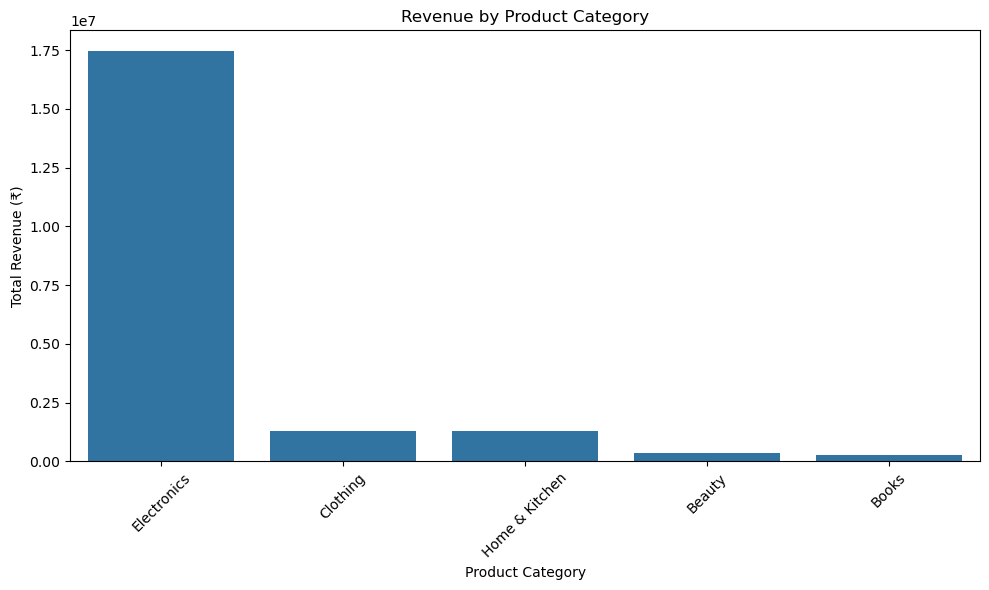

In [76]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate revenue by category
category_revenue = (
    cleaned_df.groupby("category")["total_amount"]
    .sum()
    .sort_values(ascending=False)
)

# Create bar chart
plt.figure(figsize=(10, 6))

sns.barplot(
    x=category_revenue.index,
    y=category_revenue.values
)

plt.title("Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Revenue (₹)")
plt.xticks(rotation=45)
plt.tight_layout()

# Save chart
plt.savefig("revenue_by_category.png", dpi=300, bbox_inches="tight")

plt.show()

Interpretation: The bar chart compares total revenue across product categories. The category with the highest revenue is [category name], while [category name] generates the lowest revenue. This comparison helps identify strong-performing categories and areas that may need further investigation.

Line Chart: Monthly Sales Trend

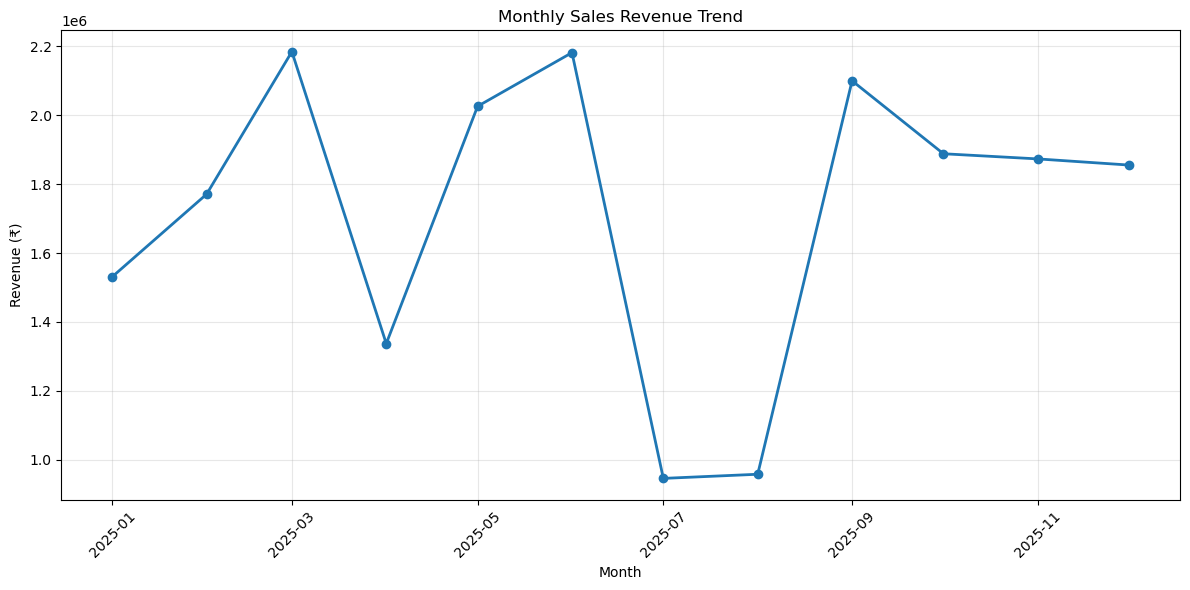

In [77]:

import pandas as pd
import matplotlib.pyplot as plt

# Ensure order_date is in datetime format
cleaned_df["order_date"] = pd.to_datetime(cleaned_df["order_date"])

# Calculate monthly revenue
monthly_sales = (
    cleaned_df
    .set_index("order_date")
    .resample("MS")["total_amount"]
    .sum()
)

# Create line chart
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    marker="o",
    linewidth=2
)

plt.title("Monthly Sales Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (₹)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()

# Save chart
plt.savefig(
    "monthly_sales_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


Monthly Sales Trend: The line chart shows how revenue changes over the observed months. Revenue reached its highest point in [month] and its lowest point in [month]. These changes can help identify periods of stronger or weaker sales.

Pie Chart: Revenue by Category

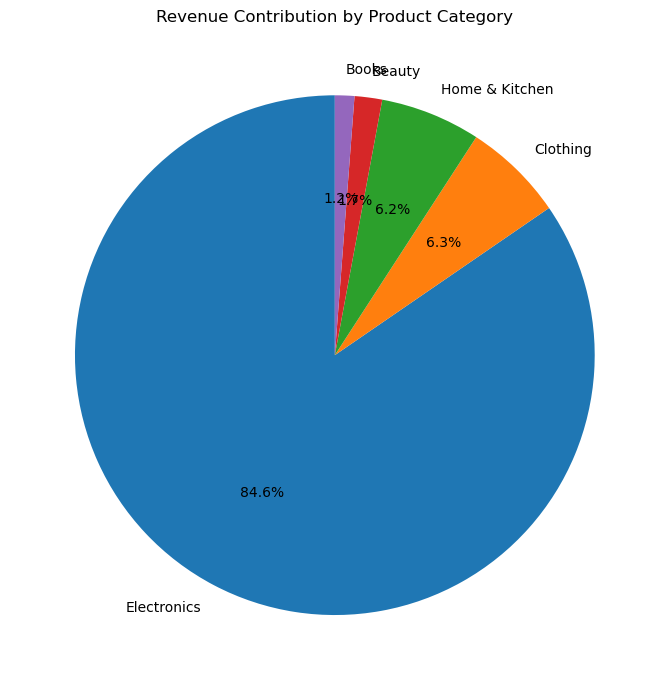

In [78]:

import matplotlib.pyplot as plt

# Calculate revenue by category
category_revenue = (
    cleaned_df.groupby("category")["total_amount"]
    .sum()
    .sort_values(ascending=False)
)

# Create pie chart
plt.figure(figsize=(9, 7))

plt.pie(
    category_revenue.values,
    labels=category_revenue.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Revenue Contribution by Product Category")
plt.tight_layout()

# Save chart
plt.savefig(
    "revenue_by_category_pie.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


Category Revenue Contribution: The pie chart illustrates each product category's share of total revenue. [Category name] contributes the largest percentage, while [category name] contributes the smallest. This helps identify which categories contribute most to overall sales.

Create an E-Commerce Sales Dashboard

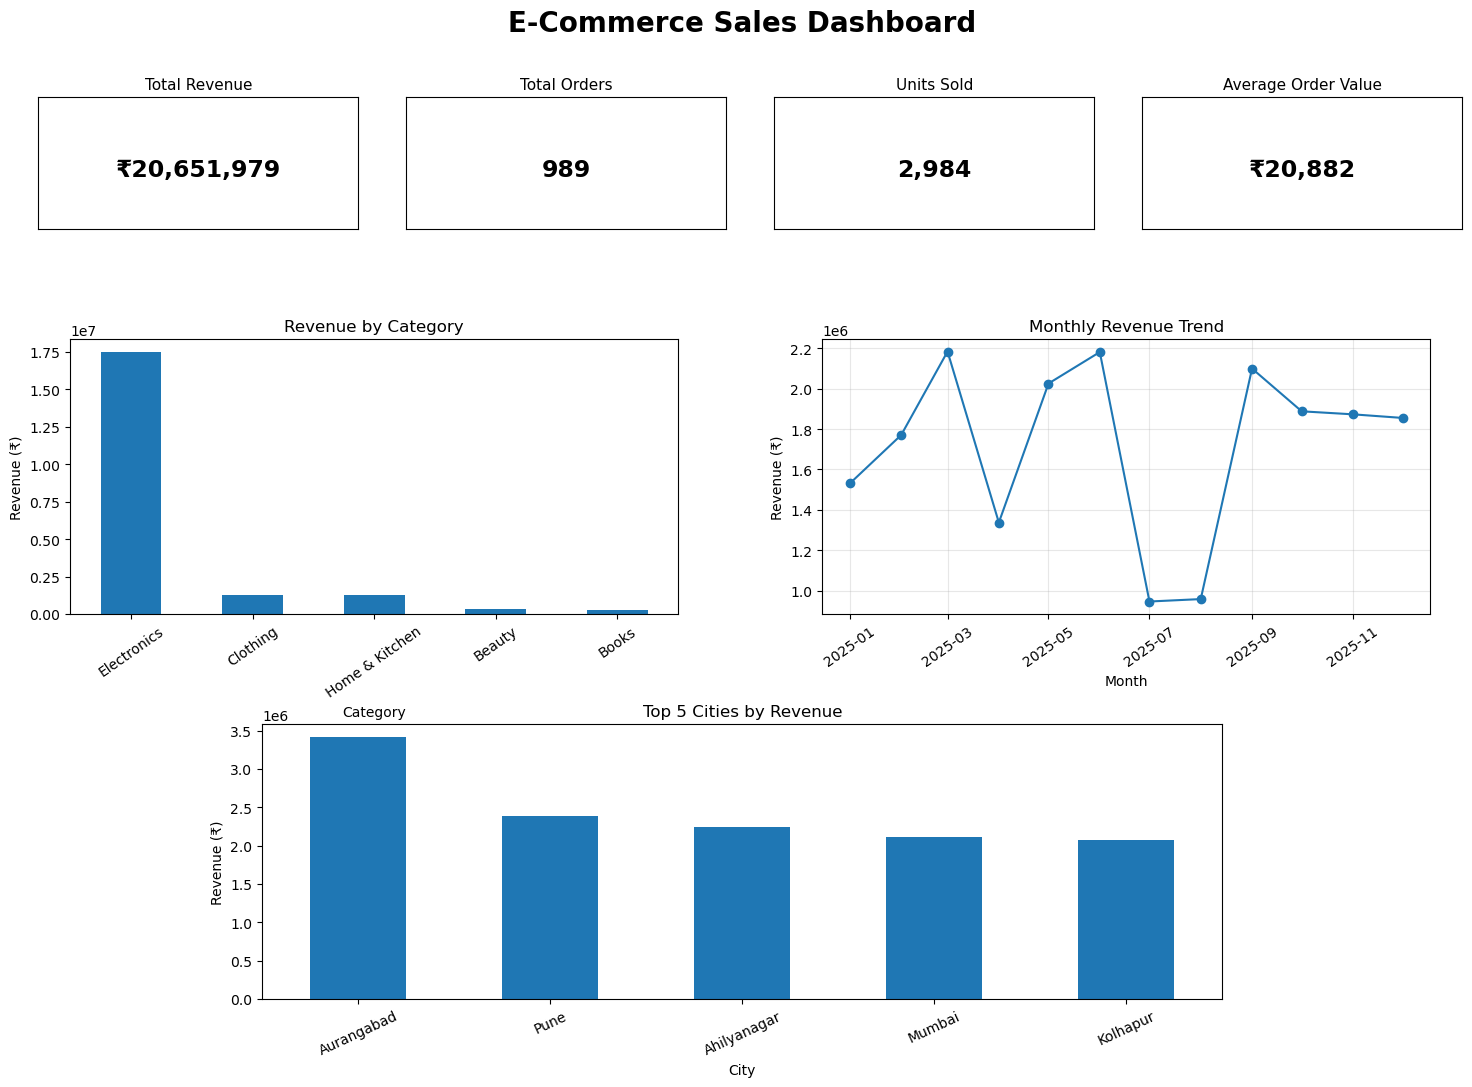

In [79]:

import pandas as pd
import matplotlib.pyplot as plt

# Prepare dashboard data
cleaned_df["order_date"] = pd.to_datetime(cleaned_df["order_date"])

total_revenue = cleaned_df["total_amount"].sum()
total_orders = cleaned_df["order_id"].nunique()
total_units = cleaned_df["quantity"].sum()
avg_order_value = total_revenue / total_orders if total_orders else 0

category_revenue = (
    cleaned_df.groupby("category")["total_amount"]
    .sum()
    .sort_values(ascending=False)
)

monthly_revenue = (
    cleaned_df.set_index("order_date")
    .resample("MS")["total_amount"]
    .sum()
)

city_revenue = (
    cleaned_df.groupby("city")["total_amount"]
    .sum()
    .sort_values(ascending=False)
    .head(5)
)

# Create dashboard layout
fig = plt.figure(figsize=(16, 11))
fig.suptitle(
    "E-Commerce Sales Dashboard",
    fontsize=20,
    fontweight="bold"
)

# KPI cards
kpis = [
    ("Total Revenue", f"₹{total_revenue:,.0f}"),
    ("Total Orders", f"{total_orders:,}"),
    ("Units Sold", f"{total_units:,}"),
    ("Average Order Value", f"₹{avg_order_value:,.0f}")
]

for i, (label, value) in enumerate(kpis):
    ax = fig.add_axes([0.06 + i * 0.23, 0.78, 0.20, 0.12])
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(label, fontsize=11)
    ax.text(
        0.5, 0.45, value,
        ha="center", va="center",
        fontsize=17, fontweight="bold"
    )
    for spine in ax.spines.values():
        spine.set_visible(True)

# Category revenue chart
ax1 = fig.add_axes([0.08, 0.43, 0.38, 0.25])
category_revenue.plot(kind="bar", ax=ax1)
ax1.set_title("Revenue by Category")
ax1.set_xlabel("Category")
ax1.set_ylabel("Revenue (₹)")
ax1.tick_params(axis="x", rotation=35)

# Monthly revenue chart
ax2 = fig.add_axes([0.55, 0.43, 0.38, 0.25])
ax2.plot(monthly_revenue.index, monthly_revenue.values, marker="o")
ax2.set_title("Monthly Revenue Trend")
ax2.set_xlabel("Month")
ax2.set_ylabel("Revenue (₹)")
ax2.tick_params(axis="x", rotation=35)
ax2.grid(True, alpha=0.3)

# Top 5 city revenue chart
ax3 = fig.add_axes([0.20, 0.08, 0.60, 0.25])
city_revenue.plot(kind="bar", ax=ax3)
ax3.set_title("Top 5 Cities by Revenue")
ax3.set_xlabel("City")
ax3.set_ylabel("Revenue (₹)")
ax3.tick_params(axis="x", rotation=25)

# Save dashboard
plt.savefig(
    "ecommerce_sales_dashboard.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [80]:
import os
print(os.path.abspath("ecommerce_sales_dashboard.png"))

C:\Users\HP\Untitled Folder\ecommerce_sales_dashboard.png


In [81]:

import pandas as pd

# Calculate final metrics from your cleaned dataset
total_revenue = cleaned_df["total_amount"].sum()
total_orders = cleaned_df["order_id"].nunique()
total_units = cleaned_df["quantity"].sum()
average_order_value = (
    total_revenue / total_orders if total_orders else 0
)

top_category = (
    cleaned_df.groupby("category")["total_amount"]
    .sum()
    .idxmax()
)

top_product = (
    cleaned_df.groupby("product_name")["total_amount"]
    .sum()
    .idxmax()
)

top_city = (
    cleaned_df.groupby("city")["total_amount"]
    .sum()
    .idxmax()
)

customer_orders = (
    cleaned_df.groupby("customer_id")["order_id"]
    .nunique()
)

repeat_customers = (customer_orders > 1).sum()

customer_revenue = cleaned_df.groupby("customer_id")[
    "total_amount"
].sum()

repeat_customer_ids = customer_orders[customer_orders > 1].index
repeat_revenue = customer_revenue.reindex(
    repeat_customer_ids
).sum()

repeat_revenue_share = (
    repeat_revenue / total_revenue * 100
    if total_revenue else 0
)

# Create report
report = f"""
# Data Science Internship — Week 1 Report

## 1. Project Objective
To clean an e-commerce dataset, perform sales analysis, identify customer
and product trends, and communicate business insights using visualizations.

## 2. Dataset Overview
- Original rows: {len(df)}
- Original columns: {len(df.columns)}
- Cleaned rows: {len(cleaned_df)}
- Columns in cleaned dataset: {len(cleaned_df.columns)}

## 3. Data Cleaning Summary
The dataset was inspected for missing values, duplicate rows, invalid
quantities, invalid prices, incorrect dates, and inconsistent categories.

Cleaning actions included:
- Removing confirmed duplicate rows.
- Standardizing column names and text categories.
- Handling missing categorical and customer values.
- Excluding invalid quantities, non-positive prices, and invalid dates.
- Recalculating Total Amount as Quantity × Unit Price.
- Saving the cleaned data separately from the raw dataset.

## 4. Sales KPI Summary
| KPI | Result |
|---|---:|
| Total Revenue | ₹{total_revenue:,.2f} |
| Total Orders | {total_orders:,} |
| Average Order Value | ₹{average_order_value:,.2f} |
| Total Units Sold | {total_units:,} |
| Top Revenue Category | {top_category} |
| Top Revenue Product | {top_product} |

## 5. Sales and Category Trends
- Highest revenue category: {top_category}
- Monthly revenue trends are shown in the monthly sales chart.
- Category revenue comparisons are shown in the category bar chart.
- Category revenue contributions are shown in the pie chart.

## 6. Customer Insights
- Repeat customers: {repeat_customers}
- Repeat-customer revenue share: {repeat_revenue_share:.2f}%
- Highest revenue city: {top_city}

Repeat customers contribute a substantial share of revenue. Customer
retention and city-level sales performance should be examined further.

## 7. Visualizations
The project includes:
1. Revenue by product category — bar chart.
2. Monthly revenue trend — line chart.
3. Revenue contribution by category — pie chart.
4. E-commerce sales dashboard — KPI cards and charts.

## 8. Key Findings
- Sales performance varies across product categories.
- Revenue can be compared across months to identify stronger and weaker periods.
- Repeat-customer revenue share provides insight into customer retention.
- City-level revenue helps identify important sales markets.

## 9. Recommendations
- Investigate the highest-revenue product categories and products.
- Develop customer-retention strategies for repeat customers.
- Review sales trends monthly and investigate unusual changes.
- Compare city performance before planning targeted marketing.
- Continue monitoring data quality and cleaning decisions.

## 10. Limitations and Assumptions
- Results depend on the supplied dataset and cleaning decisions.
- Missing customer IDs were labeled Unknown, which may affect customer counts.
- Repeated Order IDs were not automatically treated as duplicate orders.
- Invalid records were excluded according to the cleaning rules.
- Revenue is calculated from Quantity × Unit Price.
- Observed trends do not establish the causes of changes in sales.

## 11. Conclusion
The project demonstrates a complete introductory data-analysis workflow:
dataset inspection, data cleaning, KPI calculation, customer and sales
analysis, visualization, and business reporting.
"""

with open("final_report.md", "w", encoding="utf-8") as file:
    file.write(report)

print("Report created: final_report.md")
print(report)


Report created: final_report.md

# Data Science Internship — Week 1 Report

## 1. Project Objective
To clean an e-commerce dataset, perform sales analysis, identify customer
and product trends, and communicate business insights using visualizations.

## 2. Dataset Overview
- Original rows: 1010
- Original columns: 13
- Cleaned rows: 992
- Columns in cleaned dataset: 15

## 3. Data Cleaning Summary
The dataset was inspected for missing values, duplicate rows, invalid
quantities, invalid prices, incorrect dates, and inconsistent categories.

Cleaning actions included:
- Removing confirmed duplicate rows.
- Standardizing column names and text categories.
- Handling missing categorical and customer values.
- Excluding invalid quantities, non-positive prices, and invalid dates.
- Recalculating Total Amount as Quantity × Unit Price.
- Saving the cleaned data separately from the raw dataset.

## 4. Sales KPI Summary
| KPI | Result |
|---|---:|
| Total Revenue | ₹20,651,979.00 |
| Total Orders